<a href="https://colab.research.google.com/github/maribarbosaa/artigo-comparativo-modelos-redes/blob/main/experimento_preditor_redes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Teste

In [ ]:
!pip install pandas scikit-learn xgboost

In [ ]:
from google.colab import files

arquivos = files.upload()

Saving UNSW_NB15_testing-set.csv to UNSW_NB15_testing-set.csv


In [ ]:
from google.colab import files

arquivos = files.upload()

Saving UNSW_NB15_training-set.csv to UNSW_NB15_training-set.csv


In [ ]:
import pandas as pd

treino = pd.read_csv("UNSW_NB15_training-set.csv")
teste = pd.read_csv("UNSW_NB15_testing-set.csv")

print("Formato dos dados de treino:", treino.shape)
print("Formato dos dados de teste:", teste.shape)

print("\nPrimeiras linhas:")
display(treino.head())

print("\nColunas disponíveis:")
print(treino.columns.tolist())

Formato dos dados de treino: (175341, 45)
Formato dos dados de teste: (82332, 45)

Primeiras linhas:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0



Colunas disponíveis:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


1. Instalar as bibliotecas

In [ ]:
%pip install -q pandas scikit-learn xgboost matplotlib seaborn

2. Importar as bibliotecas

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import time

SEMENTE = 42

print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Bibliotecas importadas com sucesso!")

Pandas: 2.2.3
Scikit-learn: 1.6.1
XGBoost: 3.4.1
Bibliotecas importadas com sucesso!


3. Investigar as colunas e as classes

In [ ]:
print("Colunas do treinamento:")
print(treino.columns.tolist())

print("\nQuantidade de valores ausentes:")
print(treino.isnull().sum().sort_values(ascending=False).head(10))

print("\nDistribuição das classes no treinamento:")
print(treino["label"].value_counts())

print("\nProporção das classes:")
print(treino["label"].value_counts(normalize=True).round(3))

Colunas do treinamento:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Quantidade de valores ausentes:
id         0
dur        0
proto      0
service    0
state      0
spkts      0
dpkts      0
sbytes     0
dbytes     0
rate       0
dtype: int64

Distribuição das classes no treinamento:
label
1    119341
0     56000
Name: count, dtype: int64

Proporção das classes:
label
1    0.681
0    0.319
Name: proportion, dtype: float64


4. Visualizar o balanceamento dos dados

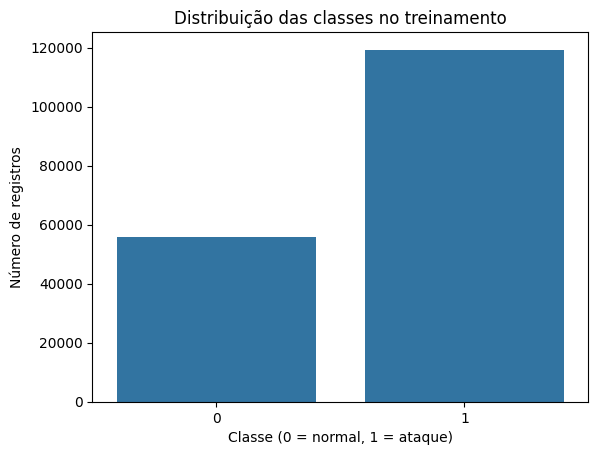

In [ ]:
contagem = treino["label"].value_counts().sort_index()

sns.barplot(x=contagem.index.astype(str), y=contagem.values)

plt.title("Distribuição das classes no treinamento")
plt.xlabel("Classe (0 = normal, 1 = ataque)")
plt.ylabel("Número de registros")
plt.show()